# A/B-тест рекламной рассылки: от плана до бизнес-решения

**Учебный пет-проект на Python · Реальные данные Hillstrom / MineThatData, 2008**

Интернет-магазин хочет понять, увеличивает ли рекламное письмо продажи.
Сравниваю клиентов без рассылки (**A**) с клиентами, которым назначено письмо с мужскими товарами (**B**).
Основная метрика — **сумма покупок за 14 дней в расчёте на одного назначенного клиента**, включая нулевые покупки.




## Данные и их происхождение

Автор Kevin Hillstrom опубликовал эксперимент с **64 000 клиентами**. Каждому случайно назначали один из
трёх вариантов: письмо с мужскими товарами, письмо с женскими товарами или отсутствие письма.
Результаты отслеживались две недели. Для основного сравнения использую **No E-Mail и Mens E-Mail**;
третью группу не включаю в проверку гипотезы. Название письма не означает пол получателя.

[Описание автора](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html) ·
[Документация копии scikit-uplift](https://www.uplift-modeling.com/en/latest/api/datasets/fetch_hillstrom.html).

| Поле | Значение | Когда измерено |
|---|---|---|
| `segment` | Назначенный вариант рассылки | При распределении |
| `history` | Сумма покупок за предшествующий год, USD | До рассылки; признак CUPED |
| `recency` | Число месяцев с последней покупки | До рассылки |
| `history_segment` | Категория прошлых трат | До рассылки |
| `mens`, `womens` | Покупал ли соответствующие товары раньше | До рассылки |
| `zip_code`, `channel`, `newbie` | Категория местности, прошлый канал, признак нового клиента | До рассылки |
| `visit` | Посетил ли сайт | За следующие 14 дней |
| `conversion` | Купил ли что-нибудь | За следующие 14 дней |
| `spend` | Сумма покупок, USD; 0 для не купивших | За следующие 14 дней |

## 1. Планирование эксперимента

**Проблема бизнеса:** рассылка требует ресурсов и может раздражать клиентов. Нужно оценить, создаёт ли
она дополнительные продажи по сравнению с отсутствием письма.

| Пункт плана | Решение для учебного проекта |
|---|---|
| Воздействие | Одно письмо с мужскими товарами |
| A / B | Без письма / назначено письмо |
| Популяция | Клиенты с покупкой за последние 12 месяцев, как в источнике |
| Единица рандомизации и анализа | Один клиент; предполагаем одну строку на клиента по описанию автора |
| Основная метрика | Средний `spend` на всех назначенных клиентов, включая нули |
| Нулевая гипотеза H0 | Средний `spend` в A и B одинаков: μB − μA = 0 |
| Альтернатива H1 | Средние различаются: μB − μA ≠ 0; тест двусторонний |
| Основной метод | t-тест Уэлча для независимых групп, `equal_var=False` |
| Ошибка первого рода α | 0,05: контроль частоты ложных отклонений H0 в повторениях при выполненных предпосылках |
| Мощность | 80% при эффекте выбранного размера и выполненных плановых допущениях |
| Плановый MDE | +0,50 USD на клиента — учебное допущение о размере эффекта для расчёта выборки |
| Плановое стандартное отклонение | 15 USD в каждой группе — учебное допущение; в реальности берётся из независимого пилота/истории такой же метрики |
| Распределение в будущем A/B | 1:1; фактический исторический эксперимент был трёхгрупповым 1:1:1 |
| Окно наблюдения | Полные 14 дней после назначения; для разовой кампании — фиксированный состав и общий старт |
| Правило завершения | Размер набран, окно наблюдения завершено; не останавливаемся при первом p < 0,05 |
| Вторичные показатели | Конверсия и визиты — описательно, без отдельных заявлений о статистической значимости |
| Защитные показатели для будущего запуска | Отписки, жалобы, стоимость кампании, маржа и возвраты; в этой таблице их нет |

**Критерий решения:** положительная разница основной метрики с 95% ДИ выше нуля даёт основания обсуждать
дальнейший запуск. 



### 1.1. Импорты и настройки

In [1]:
import hashlib
import lzma
from base64 import b64decode
from io import BytesIO

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from statsmodels.stats.power import TTestIndPower
from IPython.display import display, Markdown

ALPHA = 0.05
POWER = 0.80
MDE_USD = 0.50
SIGMA_PLAN_USD = 15.0
ALPHA_SRM = 0.001
FOLLOWUP_DAYS = 14
AA_REPEATS = 500
RANDOM_SEED = 20261106
N_BUCKETS = 100
ASSIGNMENT_SALT = 'hillstrom_assignment_demo_v1'
AA_SALT = 'hillstrom_aa_demo_v1'
BUCKET_SALT = 'hillstrom_analysis_buckets_v1'

CONTROL_LABEL = 'No E-Mail'
TREATMENT_LABEL = 'Mens E-Mail'
GROUP_NAMES = {'A': 'A: без письма', 'B': 'B: письмо'}
COLORS = {'A': '#576b80', 'B': '#167d9a'}

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.family': 'DejaVu Sans'})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda value: f'{value:.6g}')

print('Настройки загружены. Следующий раздел — расчёт выборки.')

Настройки загружены. Следующий раздел — расчёт выборки.


## 2. Считаем необходимый размер выборки

**Вопрос:** сколько клиентов нужно в каждой группе, чтобы с вероятностью около 80% обнаружить эффект
0,50 USD, если он действительно есть и стандартное отклонение равно 15 USD?

Для равных групп и планового одинакового разброса нормальное приближение даёт:

$$n \approx 2 (z_{1-\alpha/2}+z_{\mathrm{power}})^2\frac{\sigma^2}{\Delta^2}.$$

`n` — число клиентов **в одной группе**, `Δ` — MDE в долларах, `σ` — плановое стандартное отклонение.
После приближения уточняю размер численно через `TTestIndPower`. Это расчёт для двух независимых средних
при одинаковых плановых дисперсиях; для Welch с разными ожидаемыми дисперсиями и редкими покупками
план желательно дополнительно проверять симуляциями на независимых исторических данных.
Наши 15 USD и 0,50 USD заданы для учебного сценария, не оценены по наблюдаемому A/B-эффекту.

Нормальное приближение: 14,128 клиентов на группу
Уточнение через t-распределение: 14,129 клиентов на группу
Всего для будущего A/B с распределением 1:1: 28,258
После назначения каждому нужно наблюдение длиной 14 дней.


"MDE, USD",0.25,0.5,1
"σ, USD",,,
10,25118,6281,1571
15,56513,14129,3533
20,100467,25118,6281


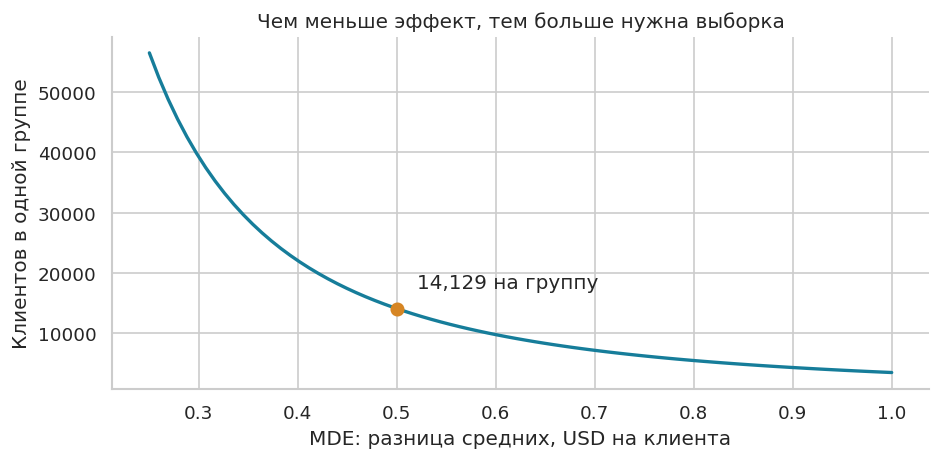

In [2]:
z_alpha = stats.norm.ppf(1 - ALPHA / 2)
z_power = stats.norm.ppf(POWER)
n_normal = int(np.ceil(2 * (z_alpha + z_power)**2 * SIGMA_PLAN_USD**2 / MDE_USD**2))

power_solver = TTestIndPower()
n_required = int(np.ceil(power_solver.solve_power(
    effect_size=MDE_USD / SIGMA_PLAN_USD,
    alpha=ALPHA, power=POWER, ratio=1.0, alternative='two-sided'
)))

print(f'Нормальное приближение: {n_normal:,} клиентов на группу')
print(f'Уточнение через t-распределение: {n_required:,} клиентов на группу')
print(f'Всего для будущего A/B с распределением 1:1: {2 * n_required:,}')
print(f'После назначения каждому нужно наблюдение длиной {FOLLOWUP_DAYS} дней.')

sensitivity_rows = []
for sigma in [10.0, 15.0, 20.0]:
    for mde in [0.25, 0.50, 1.00]:
        required = int(np.ceil(power_solver.solve_power(
            effect_size=mde / sigma, alpha=ALPHA, power=POWER,
            ratio=1.0, alternative='two-sided'
        )))
        sensitivity_rows.append({'σ, USD': sigma, 'MDE, USD': mde,
                                 'Клиентов на группу': required})
sample_size_table = pd.DataFrame(sensitivity_rows)
display(sample_size_table.pivot(index='σ, USD', columns='MDE, USD',
                                values='Клиентов на группу'))

mde_grid = np.linspace(0.25, 1.0, 80)
n_grid = [power_solver.solve_power(effect_size=d / SIGMA_PLAN_USD,
          alpha=ALPHA, power=POWER, ratio=1.0) for d in mde_grid]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mde_grid, n_grid, color=COLORS['B'], linewidth=2)
ax.scatter([MDE_USD], [n_required], color='#d68523', s=55, zorder=3)
ax.annotate(f'{n_required:,} на группу', (MDE_USD, n_required),
            xytext=(12, 12), textcoords='offset points')
ax.set(title='Чем меньше эффект, тем больше нужна выборка',
       xlabel='MDE: разница средних, USD на клиента', ylabel='Клиентов в одной группе')
fig.tight_layout()
plt.show()

**Что читаем в результате.** При выбранных допущениях нужно **14 129 клиентов на группу**, всего 28 258.
Если допустимый для обнаружения эффект уменьшить вдвое, выборка вырастет примерно в четыре раза.
Наличие нужного числа строк не гарантирует правильность эксперимента: важны рандомизация, качество
логов, независимость клиентов и полное окно наблюдения. Ниже сравним исторические размеры с этим
учебным ориентиром. «Наблюдаемую мощность» по найденному эффекту не рассчитываем.

## 3. Загружаем CSV

Исходный `hillstrom.csv` включён в ноутбук. Нажми **Run All**, чтобы загрузить данные и выполнить расчёты по порядку.

In [3]:
# Исходный hillstrom.csv в сжатом виде (XZ и Base64).
HILLSTROM_CSV_XZ_BASE64 = (
    '...'
)

In [4]:
EXPECTED_CSV_SHA256 = '00a6a868e05a9ffe7382da51629f6d6dce88c5acfc945e79d314ebc78fd3a2c0'

csv_bytes = lzma.decompress(b64decode(HILLSTROM_CSV_XZ_BASE64, validate=True))
csv_sha256 = hashlib.sha256(csv_bytes).hexdigest()
if csv_sha256 != EXPECTED_CSV_SHA256:
    raise ValueError('Встроенная копия hillstrom.csv повреждена. Заново скачай ноутбук.')

df = pd.read_csv(BytesIO(csv_bytes))
df.insert(0, 'user_id', np.arange(1, len(df) + 1))
print('Загружен встроенный hillstrom.csv')
print('Размер:', df.shape)
print('SHA-256:', csv_sha256)
print('user_id — созданный номер строки, а не исходный ID клиента.')
display(df.head())

Загружен встроенный hillstrom.csv
Размер: (64000, 13)
SHA-256: 00a6a868e05a9ffe7382da51629f6d6dce88c5acfc945e79d314ebc78fd3a2c0
user_id — созданный номер строки, а не исходный ID клиента.


,user_id,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,1,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0
1,2,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0
2,3,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0
3,4,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0
4,5,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0


## 4. Проверяем данные и фактическое распределение

**SRM (Sample Ratio Mismatch)** проверяет, соответствует ли число строк запланированным долям.
Здесь известен исходный план 1:1:1. Для выбранной пары ожидаем 1:1.
Использую диагностический порог 0,001, отдельно от α основного теста.
Отсутствие SRM не подтверждает автоматически исправность всей экспериментальной системы.

Пропуски по столбцам:


,Пропусков
user_id,0
recency,0
history_segment,0
history,0
mens,0
womens,0
zip_code,0
newbie,0
channel,0
segment,0


Повторений набора всех исходных полей: 6,562. Строки не удаляю.
Доступные проверки допустимости значений выполнены.


,Клиентов
segment,
Mens E-Mail,21307
No E-Mail,21306
Womens E-Mail,21387


SRM исходных трёх групп, p-value = 0.903693
SRM выбранной пары, p-value = 0.996135
На заданном пороге SRM не обнаружен. Это одна из проверок, не гарантия валидности.


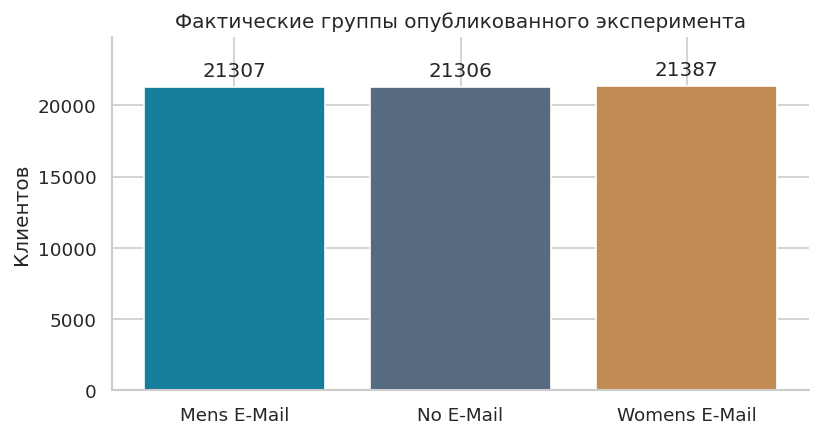

In [5]:
required_columns = {'recency', 'history_segment', 'history', 'mens', 'womens',
                    'zip_code', 'newbie', 'channel', 'segment', 'visit', 'conversion', 'spend'}
assert required_columns.issubset(df.columns)
assert len(df) == 64000
assert df[list(required_columns)].isna().sum().sum() == 0
assert set(df['segment']) == {'No E-Mail', 'Mens E-Mail', 'Womens E-Mail'}
assert (df[['history', 'spend']] >= 0).all().all()
for column in ['mens', 'womens', 'newbie', 'visit', 'conversion']:
    assert df[column].isin([0, 1]).all(), column
assert df['recency'].between(1, 12).all()
assert (df['conversion'] <= df['visit']).all()
assert ((df['spend'] > 0) == (df['conversion'] == 1)).all()

print('Пропуски по столбцам:')
display(df.isna().sum().to_frame('Пропусков'))
identical_feature_rows = df.drop(columns='user_id').duplicated().sum()
print(f'Повторений набора всех исходных полей: {identical_feature_rows:,}. Строки не удаляю.')
print('Доступные проверки допустимости значений выполнены.')

original_counts = df['segment'].value_counts().sort_index()
srm_all = stats.chisquare(original_counts.to_numpy(),
                         f_exp=np.repeat(len(df) / 3, 3))
display(original_counts.to_frame('Клиентов'))
print(f'SRM исходных трёх групп, p-value = {srm_all.pvalue:.6f}')

ab = df.loc[df['segment'].isin([CONTROL_LABEL, TREATMENT_LABEL])].copy()
ab['group'] = ab['segment'].map({CONTROL_LABEL: 'A', TREATMENT_LABEL: 'B'})
pair_counts = ab['group'].value_counts().reindex(['A', 'B'])
srm_pair = stats.chisquare(pair_counts.to_numpy(),
                          f_exp=np.repeat(len(ab) / 2, 2))
print(f'SRM выбранной пары, p-value = {srm_pair.pvalue:.6f}')
if min(srm_all.pvalue, srm_pair.pvalue) < ALPHA_SRM:
    raise ValueError('Обнаружен SRM. Сначала выясни причину дисбаланса, затем анализируй эффект.')
print('На заданном пороге SRM не обнаружен. Это одна из проверок, не гарантия валидности.')

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(original_counts.index, original_counts.values, color=['#167d9a', '#576b80', '#c08c54'])
ax.bar_label(bars, fmt='%.0f', padding=4)
ax.set(title='Фактические группы опубликованного эксперимента', ylabel='Клиентов')
ax.set_ylim(0, original_counts.max() * 1.16)
fig.tight_layout()
plt.show()

### 4.1. Сопоставимость признаков до воздействия

Сравниваем исторические характеристики через **SMD** — разницу средних, выраженную в стандартных
отклонениях. Значение около нуля означает небольшое наблюдаемое различие. Порог 0,1 — условный
ориентир, не доказательство правильной рандомизации. Не перебираем разбиения, чтобы получить красивый баланс.

In [6]:
balance_rows = []
for column in ['history', 'recency', 'mens', 'womens', 'newbie']:
    a_values = ab.loc[ab['group'] == 'A', column]
    b_values = ab.loc[ab['group'] == 'B', column]
    scale = np.sqrt((a_values.var(ddof=1) + b_values.var(ddof=1)) / 2)
    smd = (b_values.mean() - a_values.mean()) / scale if scale else np.nan
    balance_rows.append({'Признак до рассылки': column, 'Среднее A': a_values.mean(),
                         'Среднее B': b_values.mean(), 'SMD': smd})
balance_table = pd.DataFrame(balance_rows)
display(balance_table)
print('Эти сравнения используют только признаки до рассылки, а не результаты эксперимента.')

,Признак до рассылки,Среднее A,Среднее B,SMD
0,history,240.883,242.836,0.00761287
1,recency,5.74969,5.77364,0.00683153
2,mens,0.553224,0.550946,-0.00458233
3,womens,0.547639,0.551415,0.00758893
4,newbie,0.501971,0.501525,-0.000891895


Эти сравнения используют только признаки до рассылки, а не результаты эксперимента.


## 5. Хеширование с солью

Берём стабильный ID, добавляем **соль эксперимента** — строку-настройку, вычисляем SHA-256 и превращаем
первые 64 бита хеша в число. Нижняя половина диапазона отправляет клиента в A, верхняя — в B.
Одинаковые ID и соль дают одинаковую группу при повторном запуске. Для другого эксперимента задаём
другую соль. В середине действующего эксперимента её не меняем.


In [7]:
def salted_hash64(user_id, salt):
    payload = f'{salt}|{int(user_id)}'.encode('utf-8')
    return int.from_bytes(hashlib.sha256(payload).digest()[:8], byteorder='big')

def assign_demo_group(user_id, salt):
    return 'A' if salted_hash64(user_id, salt) < 2**63 else 'B'

demo = df[['user_id', 'segment']].head(12).copy()
demo['Новая учебная группа'] = demo['user_id'].map(lambda uid: assign_demo_group(uid, ASSIGNMENT_SALT))
demo['Повтор с той же солью'] = demo['user_id'].map(lambda uid: assign_demo_group(uid, ASSIGNMENT_SALT))
demo['Другая соль'] = demo['user_id'].map(lambda uid: assign_demo_group(uid, 'another_experiment_v1'))
assert demo['Новая учебная группа'].equals(demo['Повтор с той же солью'])
display(demo)

demo_assignment = df['user_id'].map(lambda uid: assign_demo_group(uid, ASSIGNMENT_SALT))
display(demo_assignment.value_counts().sort_index().to_frame('Число в демонстрационном разбиении'))
print('Фактические A/B-группы не изменены.')

,user_id,segment,Новая учебная группа,Повтор с той же солью,Другая соль
0,1,Womens E-Mail,A,A,A
1,2,No E-Mail,A,A,B
2,3,Womens E-Mail,B,B,B
3,4,Mens E-Mail,B,B,B
4,5,Womens E-Mail,B,B,A
5,6,Womens E-Mail,B,B,A
6,7,Womens E-Mail,A,A,B
7,8,Womens E-Mail,B,B,B
8,9,Mens E-Mail,A,A,A
9,10,Womens E-Mail,B,B,B


,Число в демонстрационном разбиении
user_id,
A,31976
B,32024


Фактические A/B-группы не изменены.


## 6. A/A-тест на контрольной группе



В опубликованных данных отдельного настоящего A/A нет. Поэтому беру **только No E-Mail** и делю этих
клиентов хешированием на две части. Условия у всех одинаковые: письма не было.
Это офлайн-проверка расчётов, она не проверяет доставку писем и производственную систему рандомизации.
Соль фиксирована, не подбирается ради p-value > 0,05.

In [8]:
aa = df.loc[df['segment'] == CONTROL_LABEL, ['user_id', 'spend']].copy()
aa['aa_group'] = aa['user_id'].map(lambda uid: assign_demo_group(uid, AA_SALT))
aa_a = aa.loc[aa['aa_group'] == 'A', 'spend'].to_numpy()
aa_b = aa.loc[aa['aa_group'] == 'B', 'spend'].to_numpy()
aa_welch = stats.ttest_ind(aa_b, aa_a, equal_var=False, alternative='two-sided')
aa_srm = stats.chisquare([len(aa_a), len(aa_b)])

display(aa.groupby('aa_group').agg(Клиентов=('spend', 'size'),
                                  Средние_покупки_USD=('spend', 'mean')))
print(f'A/A: p-value Welch = {aa_welch.pvalue:.6f}')
print(f'A/A: p-value SRM = {aa_srm.pvalue:.6f}')
print('p > 0,05 означает отсутствие оснований отклонить H0 в этой проверке, а не доказанное равенство.')

,Клиентов,Средние_покупки_USD
aa_group,,
A,10568,0.727521
B,10738,0.579241


A/A: p-value Welch = 0.351049
A/A: p-value SRM = 0.244158
p > 0,05 означает отсутствие оснований отклонить H0 в этой проверке, а не доказанное равенство.


### 6.1. Слабости A/A

При верной нулевой гипотезе и корректном тесте ложное отклонение всё равно возможно примерно в 5%
повторений при α = 0,05. Показываю 500 новых случайных делений того же контроля на равные части.


Доля p < 0.05: 5.6% (28 из 500)
При идеальной калибровке ориентир — 5%; случайные отклонения и приближение теста возможны.


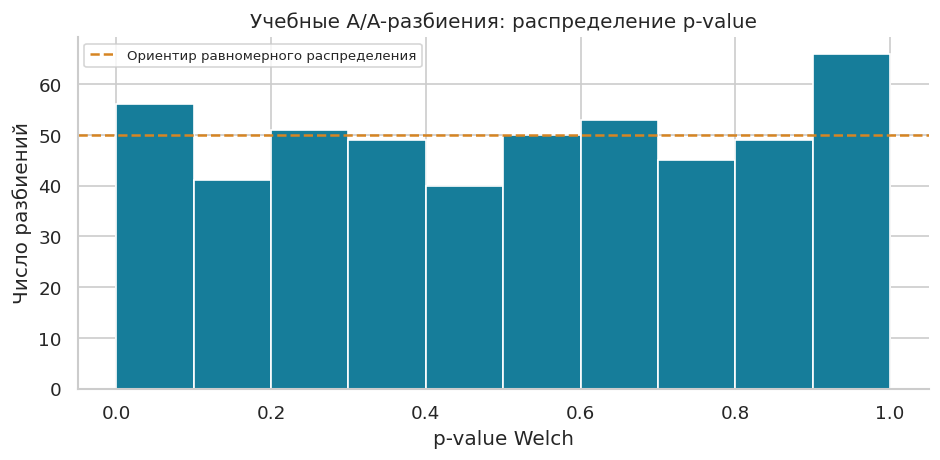

In [9]:
rng_aa = np.random.default_rng(RANDOM_SEED)
control_spend = aa['spend'].to_numpy()
half = len(control_spend) // 2
aa_pvalues = np.empty(AA_REPEATS)
for repeat in range(AA_REPEATS):
    permutation = rng_aa.permutation(len(control_spend))
    left = control_spend[permutation[:half]]
    right = control_spend[permutation[half:]]
    aa_pvalues[repeat] = stats.ttest_ind(right, left, equal_var=False).pvalue

aa_rejection_rate = (aa_pvalues < ALPHA).mean()
print(f'Доля p < {ALPHA:.2f}: {aa_rejection_rate:.1%} ({(aa_pvalues < ALPHA).sum()} из {AA_REPEATS})')
print('При идеальной калибровке ориентир — 5%; случайные отклонения и приближение теста возможны.')

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(aa_pvalues, bins=np.linspace(0, 1, 11), color=COLORS['B'], edgecolor='white')
ax.axhline(AA_REPEATS / 10, color='#d68523', linestyle='--', label='Ориентир равномерного распределения')
ax.set(title='Учебные A/A-разбиения: распределение p-value', xlabel='p-value Welch', ylabel='Число разбиений')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

**Интерпретация.** В единственном зафиксированном A/A p-value около **0,351**: оснований заявлять
различие нет. Это не доказательство нулевого эффекта и не повод перебирать соли.
Гистограмма показывает поведение метода на контрольных данных. В реальном A/A дополнительно
проверяли бы назначение пользователей, сохранность событий, метрики и полные окна наблюдения.

## 7. Смотрим фактические A/B-метрики и выбираем метод

Анализируем клиентов **по исходному назначению**, включая тех, кто ничего не купил.
Сравнение только покупателей ответило бы на другой вопрос и могло бы внести смещение.

| Метод | На какой вопрос отвечает | Роль в проекте |
|---|---|---|
| Welch t-test | Различается ли средняя сумма покупок на клиента? | Основной тест бизнес-метрики |
| Манна—Уитни | Есть ли различие рангов/распределений? | Дополнительный взгляд; не тест среднего |
| CUPED в форме ANCOVA | Как оценить разницу средних, учитывая признак до рассылки? | Оценка чувствительности и точности |
| Бакеты + дельта-метод | Как сохранить среднюю выручку на клиента при анализе агрегатов? | Демонстрация агрегации и стандартной ошибки |

Для Welch нужны независимые наблюдения и конечная дисперсия. Разбросы групп могут различаться.
Покупки сильно скошены и редки; нормальность самих покупок не предполагается. При большой выборке
используем приближение для разницы средних, помня о хвостах и небольшом числе покупателей.


,Клиентов,Покупателей,"Среднее, USD","Медиана, USD",Конверсия,Визиты,Без покупки
group,,,,,,,
A,21306,122,$0.653,$0.000,0.57%,10.62%,99.43%
B,21307,267,$1.423,$0.000,1.25%,18.28%,98.75%


В обеих группах достигнут учебный ориентир выборки: True


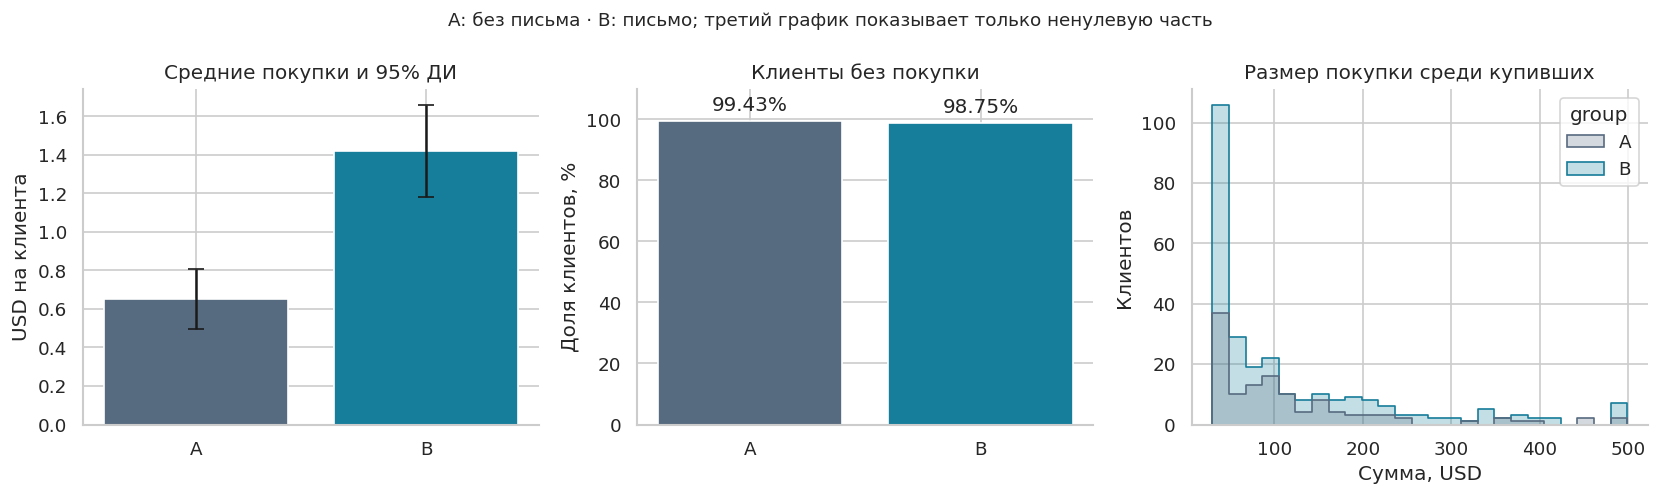

Во всех тестах ниже нулевые покупки сохранены. Последняя гистограмма ограничена только для рисунка.


In [10]:
summary = ab.groupby('group').agg(
    clients=('spend', 'size'), buyers=('conversion', 'sum'),
    mean_spend=('spend', 'mean'), median_spend=('spend', 'median'),
    std_spend=('spend', 'std'), conversion=('conversion', 'mean'), visit_rate=('visit', 'mean')
).reindex(['A', 'B'])
summary['zero_share'] = ab.assign(zero=ab['spend'].eq(0)).groupby('group')['zero'].mean()
summary['meets_educational_sample_plan'] = summary['clients'] >= n_required
summary_display = summary[['clients', 'buyers', 'mean_spend', 'median_spend',
                           'conversion', 'visit_rate', 'zero_share']].copy()
for column in ['mean_spend', 'median_spend']:
    summary_display[column] = summary_display[column].map(lambda value: f'${value:.3f}')
for column in ['conversion', 'visit_rate', 'zero_share']:
    summary_display[column] = summary_display[column].map(lambda value: f'{value:.2%}')
display(summary_display.rename(columns={'clients': 'Клиентов', 'buyers': 'Покупателей',
    'mean_spend': 'Среднее, USD', 'median_spend': 'Медиана, USD',
    'conversion': 'Конверсия', 'visit_rate': 'Визиты', 'zero_share': 'Без покупки'}))
print('В обеих группах достигнут учебный ориентир выборки:',
      summary['meets_educational_sample_plan'].all())

a = ab.loc[ab['group'] == 'A', 'spend'].to_numpy()
b = ab.loc[ab['group'] == 'B', 'spend'].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
positions = np.arange(2)
group_means = summary['mean_spend'].to_numpy()
group_se = summary['std_spend'].to_numpy() / np.sqrt(summary['clients'].to_numpy())
axes[0].bar(positions, group_means, yerr=stats.norm.ppf(.975) * group_se,
            capsize=5, color=[COLORS['A'], COLORS['B']])
axes[0].set(xticks=positions, xticklabels=['A', 'B'], ylabel='USD на клиента', title='Средние покупки и 95% ДИ')
zero_bars = axes[1].bar(positions, summary['zero_share'] * 100, color=[COLORS['A'], COLORS['B']])
axes[1].bar_label(zero_bars, fmt='%.2f%%', padding=4)
axes[1].set(xticks=positions, xticklabels=['A', 'B'], ylim=(0, 110), ylabel='Доля клиентов, %', title='Клиенты без покупки')
positive_spend = ab.loc[ab['spend'] > 0]
sns.histplot(data=positive_spend, x='spend', hue='group', hue_order=['A', 'B'],
             palette=COLORS, bins=25, element='step', ax=axes[2])
axes[2].set(title='Размер покупки среди купивших', xlabel='Сумма, USD', ylabel='Клиентов')
fig.suptitle('A: без письма · B: письмо; третий график показывает только ненулевую часть', fontsize=11)
fig.tight_layout()
plt.show()
print('Во всех тестах ниже нулевые покупки сохранены. Последняя гистограмма ограничена только для рисунка.')

## 8. Основной тест: t-тест Уэлча и доверительный интервал

Сравниваем **B минус A**, чтобы положительное число означало рост от письма.
`equal_var=False` выбирает вариант Уэлча, не требующий одинаковой дисперсии.
`alternative='two-sided'` означает, что тест допускает изменение в обе стороны.
Вместе с p-value считаем размер эффекта и 95% доверительный интервал разницы средних.

In [11]:
def welch_analysis(control, treatment, alpha=0.05):
    control = np.asarray(control, dtype=float)
    treatment = np.asarray(treatment, dtype=float)
    result = stats.ttest_ind(treatment, control, equal_var=False, alternative='two-sided')
    delta = treatment.mean() - control.mean()
    v_a = control.var(ddof=1) / len(control)
    v_b = treatment.var(ddof=1) / len(treatment)
    se = np.sqrt(v_a + v_b)
    dof = (v_a + v_b)**2 / (v_a**2 / (len(control) - 1) + v_b**2 / (len(treatment) - 1))
    critical = stats.t.ppf(1 - alpha / 2, dof)
    return {'effect': delta, 'se': se, 'df': dof,
            'ci_low': delta - critical * se, 'ci_high': delta + critical * se,
            'pvalue': float(result.pvalue), 'statistic': float(result.statistic)}

primary = welch_analysis(a, b, ALPHA)
relative_lift = primary['effect'] / a.mean()
conversion_delta_pp = (summary.loc['B', 'conversion'] - summary.loc['A', 'conversion']) * 100

print(f'A: {len(a):,} клиентов; средние покупки ${a.mean():.3f}')
print(f'B: {len(b):,} клиентов; средние покупки ${b.mean():.3f}')
print(f'Разница B − A: +${primary["effect"]:.3f} на клиента за 14 дней')
print(f'Относительная разница: {relative_lift:+.1%}')
print(f'95% ДИ: [${primary["ci_low"]:.3f}; ${primary["ci_high"]:.3f}]')
print(f'Welch t: {primary["statistic"]:.3f}; p-value: {primary["pvalue"]:.3g}')
print(f'Конверсия B − A: {conversion_delta_pp:+.3f} п.п. — только описательное сравнение')

A: 21,306 клиентов; средние покупки $0.653
B: 21,307 клиентов; средние покупки $1.423
Разница B − A: +$0.770 на клиента за 14 дней
Относительная разница: +117.9%
95% ДИ: [$0.485; $1.055]
Welch t: 5.300; p-value: 1.16e-07
Конверсия B − A: +0.681 п.п. — только описательное сравнение


### 8.1. Как интерпретировать p-value 
Здесь средние покупки выросли примерно с **0,653 до 1,423 USD**. Разница — **+0,770 USD**,
95% ДИ примерно **[+0,485; +1,055] USD**, p-value ≈ **1,16 × 10⁻⁷**.
По основному тесту есть статистические основания считать средние различающимися; знак эффекта положительный.
Относительный рост около 118% выглядит большим из-за небольшой исходной средней; абсолютный эффект
нужно оценивать отдельно. Нижняя граница ДИ чуть ниже планового MDE 0,50 USD: этот тест проверял разницу
с нулём и не подтверждает эффект строго выше 0,50 USD.

## 9. Критерий Манна—Уитни

Метод сравнивает ранги значений двух независимых групп. Стандартная нулевая гипотеза — одинаковые
распределения; в терминах попарного превосходства оцениваем
**P(YB > YA) + 0,5 × P(YB = YA)**. Равные значения учитываются наполовину.
В источнике много одинаковых нулей, поэтому используем асимптотический вариант с поправкой на совпадения.

In [12]:
mw = stats.mannwhitneyu(b, a, alternative='two-sided', method='asymptotic', use_continuity=True)
probability_superiority = mw.statistic / (len(b) * len(a))
rank_biserial = 2 * probability_superiority - 1

print(f'Медиана A: {np.median(a):.2f}; медиана B: {np.median(b):.2f}')
print(f'U-статистика для B: {mw.statistic:,.0f}')
print(f'p-value Манна—Уитни: {mw.pvalue:.3g}')
print(f'Попарное превосходство B с половиной совпадений: {probability_superiority:.4%}')
print(f'Ранговая бисериальная корреляция: {rank_biserial:.6f}')
print('Маленькое p-value здесь не означает большую разницу медиан: обе медианы равны нулю.')

Медиана A: 0.00; медиана B: 0.00
U-статистика для B: 228,527,081
p-value Манна—Уитни: 1.58e-13
Попарное превосходство B с половиной совпадений: 50.3400%
Ранговая бисериальная корреляция: 0.006801
Маленькое p-value здесь не означает большую разницу медиан: обе медианы равны нулю.


## 10. CUPED: используем данные до эксперимента

Идея: клиенты отличаются привычным объёмом покупок. Если прошлое поведение связано с будущим,
можно учесть эту часть разброса и точнее оценить эффект рассылки.

$$Y_{adj}=Y-\theta(X-\bar X).$$

`Y = spend` за две недели после рассылки. `X = history` за год **до** рассылки.
Периоды имеют разную длину — для ковариаты это допустимо, но её полезность зависит от связи с Y.
**Не используем** `visit`, `conversion` и другие результаты после назначения как ковариаты CUPED:
письмо могло повлиять на них. Нельзя также изобретать «прошлую метрику» из самого `spend`.

Здесь реализую CUPED в регрессионной форме **ANCOVA**:

$$Y=\beta_0+\tau T+\theta(X-\bar X)+\varepsilon,$$

где `T` равно 1 для B. Общий коэффициент θ оценивается с учётом группы, а τ — скорректированная
разница средних. Это эквивалентно разнице средних преобразованной метрики при выбранном θ.
Для интервала и p-value использую устойчивую к неодинаковым дисперсиям стандартную ошибку **HC3**.
Она относится к оценке коэффициента в регрессии.

Корреляция history и spend: 0.0209
Общий θ с учётом группы: 0.001217
CUPED/ANCOVA: B − A = $0.767
95% ДИ HC3: [$0.483; $1.052]
p-value HC3: 1.25e-07
Снижение объединённой внутригрупповой дисперсии метрики: 0.043%
Изменение оценённой дисперсии эффекта относительно Welch: 0.132%


,Метод,"Эффект, USD",Стандартная ошибка,p-value
0,Welch: исходная метрика,0.769827,0.145247,1.16381e-07
1,"CUPED / ANCOVA, HC3",0.76745,0.145151,1.24779e-07


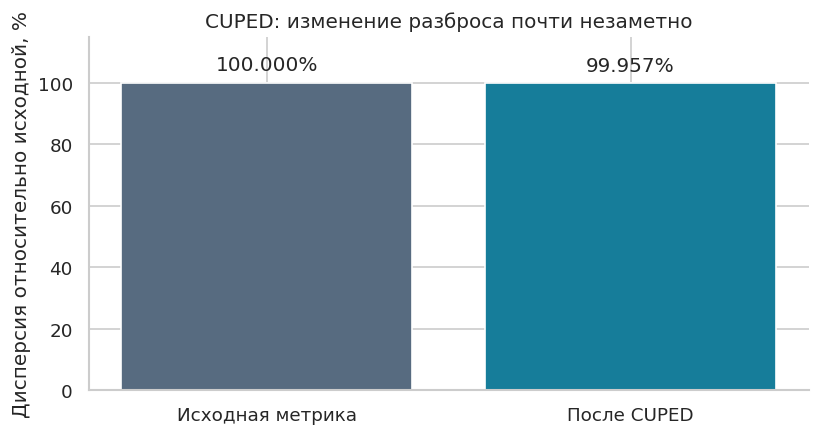

In [13]:
ab['history_centered'] = ab['history'] - ab['history'].mean()
ab['treatment'] = ab['group'].eq('B').astype(int)
design = sm.add_constant(ab[['treatment', 'history_centered']])
cuped_model = sm.OLS(ab['spend'], design).fit(cov_type='HC3', use_t=True)
theta = float(cuped_model.params['history_centered'])
ab['spend_cuped'] = ab['spend'] - theta * ab['history_centered']

cuped_ci = cuped_model.conf_int(alpha=ALPHA).loc['treatment']
cuped = {'effect': float(cuped_model.params['treatment']),
         'se': float(cuped_model.bse['treatment']),
         'ci_low': float(cuped_ci.iloc[0]), 'ci_high': float(cuped_ci.iloc[1]),
         'pvalue': float(cuped_model.pvalues['treatment'])}
cuped_means = ab.groupby('group')['spend_cuped'].mean()
assert np.isclose(cuped_means['B'] - cuped_means['A'], cuped['effect'], atol=1e-10)

correlation = ab[['history', 'spend']].corr().iloc[0, 1]
within_variances = []
for g in ['A', 'B']:
    part = ab.loc[ab['group'] == g]
    within_variances.append({'group': g, 'weight': len(part) - 1,
        'raw': part['spend'].var(ddof=1), 'adjusted': part['spend_cuped'].var(ddof=1)})
variance_table = pd.DataFrame(within_variances).set_index('group')
pooled_raw = np.average(variance_table['raw'], weights=variance_table['weight'])
pooled_adjusted = np.average(variance_table['adjusted'], weights=variance_table['weight'])
metric_variance_reduction = 1 - pooled_adjusted / pooled_raw
effect_variance_reduction = 1 - cuped['se']**2 / primary['se']**2

print(f'Корреляция history и spend: {correlation:.4f}')
print(f'Общий θ с учётом группы: {theta:.6f}')
print(f'CUPED/ANCOVA: B − A = ${cuped["effect"]:.3f}')
print(f'95% ДИ HC3: [${cuped["ci_low"]:.3f}; ${cuped["ci_high"]:.3f}]')
print(f'p-value HC3: {cuped["pvalue"]:.3g}')
print(f'Снижение объединённой внутригрупповой дисперсии метрики: {metric_variance_reduction:.3%}')
print(f'Изменение оценённой дисперсии эффекта относительно Welch: {effect_variance_reduction:.3%}')

display(pd.DataFrame({'Метод': ['Welch: исходная метрика', 'CUPED / ANCOVA, HC3'],
    'Эффект, USD': [primary['effect'], cuped['effect']],
    'Стандартная ошибка': [primary['se'], cuped['se']],
    'p-value': [primary['pvalue'], cuped['pvalue']]}))

fig, ax = plt.subplots(figsize=(7, 3.8))
heights = [100, 100 * pooled_adjusted / pooled_raw]
bars = ax.bar(['Исходная метрика', 'После CUPED'], heights, color=[COLORS['A'], COLORS['B']])
ax.bar_label(bars, labels=[f'{v:.3f}%' for v in heights], padding=5)
ax.set(ylim=(0, 115), ylabel='Дисперсия относительно исходной, %', title='CUPED: изменение разброса почти незаметно')
fig.tight_layout()
plt.show()

**Итог.** Корреляция прошлого и последующего объёма покупок около **0,021**.
Снижение дисперсии метрики — лишь около **0,043%**, поэтому CUPED здесь почти не помогает.
Дисперсия метрики и стандартная ошибка эффекта — разные величины, их изменения не обязаны совпадать.
Скорректированная оценка эффекта близка к исходной. Это содержательный результат: наличие поля «до»
не гарантирует заметного повышения чувствительности. Для будущего теста стоило бы изучить более
сопоставимое по длительности и релевантности прошлое поведение, если оно доступно до воздействия.
Не уменьшаем плановую выборку по выигрышу, найденному на этих же итоговых данных.

## 11. Бакетное преобразование

Внутри каждой фактической группы раскладываем клиентов в **100 бакетов** по отдельному хешу.
Все покупки одного клиента должны оставаться в одном бакете. Здесь уже одна строка на клиента по
описанию источника. 

В каждом бакете сохраняем `S` — сумму покупок и `N` — число клиентов. Размеры бакетов различаются.
Поэтому среднее считаем как **ΣS / ΣN**.

Для стандартной ошибки используем дельта-метод для отношения сумм. Для каждой группы g и бакета j:

$$\hat\mu_g=\frac{\sum_j S_{gj}}{\sum_j N_{gj}},\qquad
L_{gj}=\frac{S_{gj}-\hat\mu_g N_{gj}}{\bar N_g},\qquad
\widehat{Var}(\hat\mu_g)\approx\frac{s^2(L_g)}{K}.$$

Двустороннее p-value и ДИ
считаем по t-приближению со степенями свободы Welch–Satterthwaite.

In [14]:
def bucket_analysis(frame, k=100, salt=BUCKET_SALT, alpha=ALPHA):
    work = frame[['user_id', 'group', 'spend']].copy()
    # Разные префиксы дают отдельную аналитическую хеш-функцию для каждой группы.
    work['bucket'] = [salted_hash64(uid, f'{salt}|{group}') % k
                      for uid, group in zip(work['user_id'], work['group'])]
    full_index = pd.MultiIndex.from_product([['A', 'B'], range(k)], names=['group', 'bucket'])
    buckets = work.groupby(['group', 'bucket']).agg(S=('spend', 'sum'), N=('spend', 'size'))
    buckets = buckets.reindex(full_index, fill_value=0)
    variance_parts = {}
    group_means = {}
    for group in ['A', 'B']:
        part = buckets.loc[group]
        mu = part['S'].sum() / part['N'].sum()
        linearized = (part['S'] - mu * part['N']) / part['N'].mean()
        group_means[group] = mu
        variance_parts[group] = linearized.var(ddof=1) / k
    va, vb = variance_parts['A'], variance_parts['B']
    se = np.sqrt(va + vb)
    dof = (va + vb)**2 / (va**2 / (k - 1) + vb**2 / (k - 1))
    effect = group_means['B'] - group_means['A']
    critical = stats.t.ppf(1 - alpha / 2, dof)
    result = {'effect': effect, 'se': se, 'df': dof,
              'ci_low': effect - critical * se, 'ci_high': effect + critical * se,
              'pvalue': float(2 * stats.t.sf(abs(effect / se), dof))}
    return result, buckets

bucket, bucket_table = bucket_analysis(ab, N_BUCKETS)
assert np.isclose(bucket['effect'], primary['effect'], atol=1e-12)
print(f'Клиентских строк: {len(ab):,}; строк агрегатов: {len(bucket_table):,}')
display(bucket_table.head(8))
display(bucket_table.groupby(level='group')['N'].agg(['min', 'median', 'max', 'sum']))
print(f'Бакеты: B − A = ${bucket["effect"]:.3f}; SE = {bucket["se"]:.4f}')
print(f'95% ДИ: [${bucket["ci_low"]:.3f}; ${bucket["ci_high"]:.3f}]')
print(f'p-value бакетного приближения: {bucket["pvalue"]:.3g}')

bucket_sensitivity_rows = []
for k in [50, 100, 200]:
    res, _ = bucket_analysis(ab, k)
    bucket_sensitivity_rows.append({'Бакетов на группу': k, 'Эффект, USD': res['effect'],
        'SE': res['se'], 'Нижняя граница ДИ': res['ci_low'],
        'Верхняя граница ДИ': res['ci_high'], 'p-value': res['pvalue']})
bucket_sensitivity = pd.DataFrame(bucket_sensitivity_rows)
display(bucket_sensitivity)
print('100 бакетов зафиксированы заранее в настройках. Таблица 50/100/200 — анализ чувствительности, не поиск лучшего p-value.')

Клиентских строк: 42,613; строк агрегатов: 200


S    N
group bucket            
A     0           0  234
      1       66.17  209
      2      382.34  219
      3      320.09  212
      4      474.06  242
      5       29.99  221
      6      519.43  214
      7         499  207

,min,median,max,sum
group,,,,
A,181,212,253,21306
B,171,213,249,21307


Бакеты: B − A = $0.770; SE = 0.1426
95% ДИ: [$0.488; $1.051]
p-value бакетного приближения: 2.27e-07


,Бакетов на группу,"Эффект, USD",SE,Нижняя граница ДИ,Верхняя граница ДИ,p-value
0,50,0.769827,0.151481,0.468952,1.0707,1.96536e-06
1,100,0.769827,0.142568,0.48835,1.0513,2.27477e-07
2,200,0.769827,0.153381,0.46809,1.07156,8.54306e-07


100 бакетов зафиксированы заранее в настройках. Таблица 50/100/200 — анализ чувствительности, не поиск лучшего p-value.


## 12. Сводка методов и проверка вычислений

Сравниваем размер эффекта и интервалы у методов, которые оценивают среднюю сумму покупок.

,Метод,"B − A, USD",ДИ: нижняя,ДИ: верхняя,Стандартная ошибка,pvalue
0,Welch — основной,0.769827,0.48514,1.05451,0.145247,1.16381e-07
1,"CUPED / ANCOVA, HC3",0.76745,0.482951,1.05195,0.145151,1.24779e-07
2,Бакеты: 100 + дельта-метод,0.769827,0.48835,1.0513,0.142568,2.27477e-07


Отдельно Манна—Уитни: p = 1.58e-13, попарное превосходство = 50.3400%


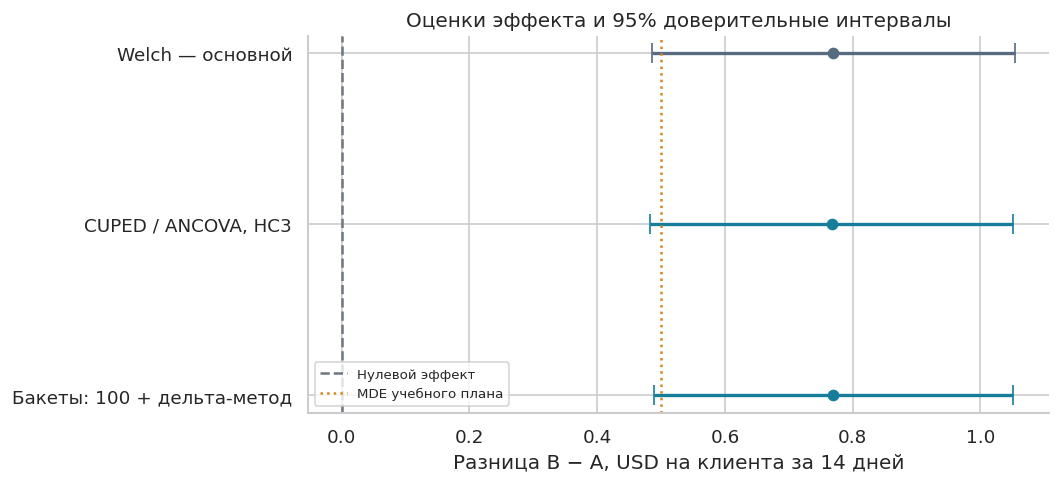

Проверки: формулы Welch, интервал SciPy, исходная метрика в бакетах и связь CUPED с регрессией согласованы.


In [15]:
effect_results = pd.DataFrame([
    {'Метод': 'Welch — основной', **primary},
    {'Метод': 'CUPED / ANCOVA, HC3', **cuped},
    {'Метод': f'Бакеты: {N_BUCKETS} + дельта-метод', **bucket}
])
display(effect_results[['Метод', 'effect', 'ci_low', 'ci_high', 'se', 'pvalue']]
    .rename(columns={'effect': 'B − A, USD', 'ci_low': 'ДИ: нижняя',
                     'ci_high': 'ДИ: верхняя', 'se': 'Стандартная ошибка'}))
print(f'Отдельно Манна—Уитни: p = {mw.pvalue:.3g}, попарное превосходство = {probability_superiority:.4%}')

fig, ax = plt.subplots(figsize=(9, 4.2))
for position, row in effect_results.iterrows():
    ax.errorbar(row['effect'], position,
        xerr=[[row['effect'] - row['ci_low']], [row['ci_high'] - row['effect']]],
        fmt='o', color=COLORS['B'] if position else COLORS['A'], capsize=6, linewidth=2)
ax.axvline(0, color='#6e7781', linestyle='--', label='Нулевой эффект')
ax.axvline(MDE_USD, color='#d68523', linestyle=':', label='MDE учебного плана')
ax.set(yticks=range(len(effect_results)), yticklabels=effect_results['Метод'],
       xlabel='Разница B − A, USD на клиента за 14 дней', title='Оценки эффекта и 95% доверительные интервалы')
ax.invert_yaxis()
ax.legend(loc='lower left', fontsize=8)
fig.tight_layout()
plt.show()

# Сверяем формулы с независимыми реализациями и сохраняем смысл метрики.
scipy_ci = stats.ttest_ind(b, a, equal_var=False).confidence_interval(confidence_level=1 - ALPHA)
assert np.allclose([primary['ci_low'], primary['ci_high']], [scipy_ci.low, scipy_ci.high])
manual_p = 2 * stats.t.sf(abs(primary['effect'] / primary['se']), primary['df'])
assert np.isclose(primary['pvalue'], manual_p, rtol=1e-10)
assert np.isclose(bucket['effect'], b.mean() - a.mean(), atol=1e-12)
assert np.isclose(cuped_means['B'] - cuped_means['A'], cuped['effect'], atol=1e-10)
assert set(ab['segment']) == {CONTROL_LABEL, TREATMENT_LABEL}
assert ab['spend'].eq(0).any()
print('Проверки: формулы Welch, интервал SciPy, исходная метрика в бакетах и связь CUPED с регрессией согласованы.')

## 13. Бизнес-интерпретация

Наблюдаемый результат относится к этой аудитории и этой кампании, а не ко всем возможным рассылкам.
По основному Welch-тесту письмо связано с положительным причинным эффектом при корректности исходной
рандомизации и прочих предпосылок эксперимента. Выбор только двух заранее обозначенных вариантов
не позволяет назвать письмо лучшим среди всех трёх вариантов.

Дополнительная выручка ещё не равна прибыли.  **Сценарный расчёт:**
маржа 40%, переменная стоимость письма 0,05 USD, будущая аналогичная аудитория 10 000 клиентов.
Интервал переносится линейно при фиксированных допущениях.

In [16]:
ASSUMED_MARGIN = 0.40
ASSUMED_EMAIL_COST = 0.05
FUTURE_AUDIENCE = 10_000

incremental_profit_per_client = primary['effect'] * ASSUMED_MARGIN - ASSUMED_EMAIL_COST
profit_low = primary['ci_low'] * ASSUMED_MARGIN - ASSUMED_EMAIL_COST
profit_high = primary['ci_high'] * ASSUMED_MARGIN - ASSUMED_EMAIL_COST
print('Учебные допущения: маржа 40%, стоимость 0,05 USD на письмо.')
print(f'Сценарная дополнительная прибыль на клиента: ${incremental_profit_per_client:.3f}')
print(f'Интервал при фиксированных допущениях: [${profit_low:.3f}; ${profit_high:.3f}]')
print(f'Для {FUTURE_AUDIENCE:,} аналогичных клиентов: около ${incremental_profit_per_client * FUTURE_AUDIENCE:,.0f}')

main_positive = primary['pvalue'] < ALPHA and primary['ci_low'] > 0
display(Markdown(
    '**Статистический вывод:** основной анализ выявил положительный эффект на среднюю сумму покупок.'
    if main_positive else
    '**Статистический вывод:** основной анализ не подтвердил положительный эффект на заданном уровне.'
))

Учебные допущения: маржа 40%, стоимость 0,05 USD на письмо.
Сценарная дополнительная прибыль на клиента: $0.258
Интервал при фиксированных допущениях: [$0.144; $0.372]
Для 10,000 аналогичных клиентов: около $2,579


**Статистический вывод:** основной анализ выявил положительный эффект на среднюю сумму покупок.

### 13.1. Вывод

В опубликованном эксперименте сравнил **21 306 клиентов без письма** и **21 307 клиентов с назначенным
письмом с мужскими товарами**. Средняя сумма покупок за две недели составила **0,653 USD в A** и
**1,423 USD в B**. Оценка разницы — **+0,770 USD на клиента**, 95% доверительный интервал —
примерно **[+0,485; +1,055] USD**. По основному t-тесту Уэлча различие статистически значимо
на уровне 0,05: **p ≈ 1,16 × 10⁻⁷**.

Критерий Манна—Уитни также указывает на различие рангов/распределений, хотя медианы обеих групп равны
нулю. CUPED с покупками за прошлый год почти не повысил точность: связь с последующими покупками
оказалась слабой. Анализ по бакетам сохранил оценку средней разницы, но дал другую приближённую
стандартную ошибку. Эти способы не использовались для выбора наиболее выгодного p-value.

В этом эксперименте клиенты с письмом в среднем купили больше. Есть основания
рассмотреть повторный контролируемый запуск, проверив актуальную экономику, отписки и жалобы.
Окончательную прибыльность по одной таблице подтвердить нельзя: в ней нет расходов, маржи и защитных метрик.